<a href="https://colab.research.google.com/github/AidaAm005/NHANES-Tobacco-Biomarkers/blob/phase-1/notebooks/phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import os
import sys
from google.colab import drive

# ۱. اتصال به گوگل درایو (هنگام اجرا یک پنجره تایید دسترسی باز می‌شود)
drive.mount('/content/drive')

# ۲. تعریف مسیر پوشه اصلی پروژه در گوگل درایو
PROJECT_ROOT = '/content/drive/MyDrive/NHANES-Tobacco-Biomarkers'

# ۳. تغییر دایرکتوری کاری کولب به ریشه پروژه
os.chdir(PROJECT_ROOT)

# ۴. افزودن ریشه پروژه به مسیرهای پایتون برای شناسایی پکیج src
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("مسیر کاری فعلی:", os.getcwd())
print("فایل‌های موجود در پوشه src:", os.listdir('src'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
مسیر کاری فعلی: /content/drive/MyDrive/NHANES-Tobacco-Biomarkers
فایل‌های موجود در پوشه src: ['data_cleaner.py', 'data_loader.py', '__pycache__', 'descriptive_stats.py']


In [12]:
import pandas as pd
from src.data_loader import fetch_raw_datasets, merge_datasets

# ۱. دریافت فایل‌ها از سرور CDC و گزارش ابعاد اولیه پیش از ادغام
raw_datasets, df_pre_merge = fetch_raw_datasets()
print("=== جدول الف-۱ (بخش اول): مشخصات و تعداد افراد هر فایل پیش از ادغام ===")
display(df_pre_merge)

# ۲. ادغام فایل‌ها بر پایه DEMO_L با کلید مشترک SEQN
df_merged_raw, df_merge_report = merge_datasets(raw_datasets)
print("\n=== جدول الف-۱ (بخش دوم): گزارش تعداد افراد قبل و بعد از هر مرحله ادغام ===")
display(df_merge_report)

=== جدول الف-۱ (بخش اول): مشخصات و تعداد افراد هر فایل پیش از ادغام ===


,File_Name,Total_Rows_Raw,Unique_SEQN_Raw,Total_Columns_Raw,Selected_Columns_Count
0,DEMO_L,11933,11933,27,10
1,SMQ_L,9015,9015,9,4
2,SMQRTU_L,7199,7199,21,9
3,SMQFAM_L,11933,11933,3,2
4,COT_L,8493,8493,5,5
5,PBCD_L,8727,8727,17,8
6,CBC_L,8727,8727,23,3



=== جدول الف-۱ (بخش دوم): گزارش تعداد افراد قبل و بعد از هر مرحله ادغام ===


,Merge_Step,Merged_File,Merge_Key,Total_Rows_Left_Join,Matched_Participants_in_Step,Cumulative_Complete_Overlap (Inner)
0,1. Base File: DEMO_L,DEMO_L,SEQN,11933,11933,11933
1,2. Merge SMQ_L,SMQ_L,SEQN,11933,9015,9015
2,3. Merge SMQRTU_L,SMQRTU_L,SEQN,11933,7199,7199
3,4. Merge SMQFAM_L,SMQFAM_L,SEQN,11933,11933,7199
4,5. Merge COT_L,COT_L,SEQN,11933,8493,7199
5,6. Merge PBCD_L,PBCD_L,SEQN,11933,8727,7199
6,7. Merge CBC_L,CBC_L,SEQN,11933,8727,7199


In [13]:
from src.data_cleaner import (
    fix_sas_zeros,
    audit_and_clean_special_codes,
    audit_duplicates_and_logic,
    audit_missing_and_ranges,
    audit_lod_censored_values
)

# ۱. اصلاح مقادیر علمی بسیار کوچک (صفرهای فرمت SAS XPT)
df_step1, n_tiny_zeros = fix_sas_zeros(df_merged_raw)
print(f"تعداد مقادیر ممیز شناور نزدیک به صفر که به 0.0 دقیق تبدیل شدند: {n_tiny_zeros} مورد\n")

# ۲. شناسایی کدهای ویژه «امتناع (7/77/777)» و «نامعلوم (9/99/999)» و تبدیل به NaN
df_cleaned, df_special_codes = audit_and_clean_special_codes(df_step1)
print("=== جدول ۵-۱: ممیزی کدهای ویژه نامعلوم و پاسخ نداده در پرسش‌نامه‌ها ===")
display(df_special_codes)

# ۳. بررسی رکوردهای تکراری، مقادیر غیرممکن و ناسازگاری‌های منطقی
df_logic_audit = audit_duplicates_and_logic(df_cleaned)
print("\n=== جدول ۵-۲: ممیزی رکوردهای تکراری، مقادیر غیرممکن و سازگاری منطقی ===")
display(df_logic_audit)

# ۴. ممیزی داده‌های گمشده و بازه مقادیر (در کل نمونه و در بزرگسالان ۲۰ سال به بالا)
df_missing_all = audit_missing_and_ranges(df_cleaned, subset_adults=False)
df_missing_adults = audit_missing_and_ranges(df_cleaned, subset_adults=True)
print("\n=== جدول ۵-۳ (الف): ممیزی داده‌های گمشده و دامنه مقادیر در کل نمونه ادغام‌شده ===")
display(df_missing_all)
print("\n=== جدول ۵-۳ (ب): ممیزی داده‌های گمشده و دامنه مقادیر در بزرگسالان (۲۰ سال و بالاتر) ===")
display(df_missing_adults)

# ۵. ممیزی مقادیر سانسورشده زیر حد تشخیص آزمایشگاه (Below LOD)
df_lod_audit = audit_lod_censored_values(df_cleaned, subset_adults=True)
print("\n=== جدول ۵-۴: ممیزی مقادیر زیر حد تشخیص دستگاه آزمایشگاه (Below LOD) ===")
display(df_lod_audit)

تعداد مقادیر ممیز شناور نزدیک به صفر که به 0.0 دقیق تبدیل شدند: 37173 مورد

=== جدول ۵-۱: ممیزی کدهای ویژه نامعلوم و پاسخ نداده در پرسش‌نامه‌ها ===


,Variable,Special_Codes_Checked,Refused_Count (7/77/777),Dont_Know_Count (9/99/999),Total_Converted_to_NaN
0,DMDEDUC2,"[7, 9]",0,11,11
1,SMQ020,"[7, 9]",7,7,14
2,SMQ040,"[7, 9]",0,0,0
3,SMD650,"[777, 999]",0,9,9
4,SMQ681,"[7, 9]",1,2,3
5,SMQ710,"[7, 9, 77, 99]",1,1,2
6,SMQ720,"[777, 999]",1,1,2
7,SMQ845,"[7, 9]",0,1,1
8,SMQ846,"[7, 9]",1,4,5
9,SMQ849,"[7, 9, 77, 99]",0,1,1



=== جدول ۵-۲: ممیزی رکوردهای تکراری، مقادیر غیرممکن و سازگاری منطقی ===


,Check_Type,Count,Decision
0,Duplicate Full Rows,0,No action needed (0 duplicates)
1,Duplicate SEQN IDs,0,1-to-1 merge verified
2,Impossible Negative Values,0,All quantitative values within valid physical ...
3,Questionnaire Skip-Pattern Violation (SMQ020=2...,0,Structural missingness confirmed
4,Discordant Self-Report (Non-smoker in SMQ but ...,188,Classify based on active recent use (SMQ681=1)...
5,Impossible Recent Days (>5 days in last 5 days),0,"Valid range [0, 5] confirmed"



=== جدول ۵-۳ (الف): ممیزی داده‌های گمشده و دامنه مقادیر در کل نمونه ادغام‌شده ===


,Variable,Total_N,Valid_N,Missing_Count,Missing_Percent (%),Min_Value,Max_Value
0,RIDAGEYR,11933,11933,0,0.00,0.0000,80.0000
1,RIAGENDR,11933,11933,0,0.00,1.0000,2.0000
2,RIDRETH3,11933,11933,0,0.00,1.0000,7.0000
3,DMDEDUC2,11933,7783,4150,34.78,1.0000,5.0000
4,INDFMPIR,11933,9892,2041,17.10,0.0000,5.0000
5,WTINT2YR,11933,11933,0,0.00,4584.4632,170968.3432
6,WTMEC2YR,11933,11933,0,0.00,0.0000,227108.2970
7,SDMVPSU,11933,11933,0,0.00,1.0000,2.0000
8,SDMVSTRA,11933,11933,0,0.00,173.0000,187.0000
9,SMQ020,11933,8121,3812,31.95,1.0000,2.0000



=== جدول ۵-۳ (ب): ممیزی داده‌های گمشده و دامنه مقادیر در بزرگسالان (۲۰ سال و بالاتر) ===


,Variable,Total_N,Valid_N,Missing_Count,Missing_Percent (%),Min_Value,Max_Value
0,RIDAGEYR,7809,7809,0,0.00,20.0000,80.0000
1,RIAGENDR,7809,7809,0,0.00,1.0000,2.0000
2,RIDRETH3,7809,7809,0,0.00,1.0000,7.0000
3,DMDEDUC2,7809,7783,26,0.33,1.0000,5.0000
4,INDFMPIR,7809,6489,1320,16.90,0.0000,5.0000
5,WTINT2YR,7809,7809,0,0.00,4584.4632,170968.3432
6,WTMEC2YR,7809,7809,0,0.00,0.0000,227108.2970
7,SDMVPSU,7809,7809,0,0.00,1.0000,2.0000
8,SDMVSTRA,7809,7809,0,0.00,173.0000,187.0000
9,SMQ020,7809,7780,29,0.37,1.0000,2.0000



=== جدول ۵-۴: ممیزی مقادیر زیر حد تشخیص دستگاه آزمایشگاه (Below LOD) ===


,Biomarker,Description,Comment_Code_Var,Total_Tested,Below_LOD_Count (Code=1),Below_LOD_Percent (%),CDC_Imputed_Value (LOD/sqrt(2))
0,LBXCOT,Serum Cotinine (ng/mL),LBDCOTLC,5521,2180,39.49,0.007
1,LBXHCOT,Serum Hydroxycotinine (ng/mL),LBDHCOLC,5522,2177,39.42,0.003
2,LBXBCD,Blood Cadmium (ug/L),LBDBCDLC,5770,45,0.78,0.046
3,LBXBPB,Blood Lead (ug/dL),LBDBPBLC,5770,0,0.00,NaN
4,LBXBSE,Blood Selenium (ug/L),LBDBSELC,5770,0,0.00,NaN


In [18]:
from src.descriptive_stats import (
    prepare_categorical_labels,
    generate_categorical_frequency_tables,
    generate_empirical_quantiles_table
)

# ۱. آماده‌سازی برچسب‌های طبقه‌ای و ساخت ۴ گروه مصرف روی بزرگسالان (۲۰ سال به بالا)
df_adults_labeled = prepare_categorical_labels(df_cleaned)

# ۲. تولید و نمایش جداول فراوانی و درصد برای متغیرهای طبقه‌ای (تسک ۶ - بخش اول)
freq_tables = generate_categorical_frequency_tables(df_adults_labeled)
print("=== جدول ۶-۱: توزیع فراوانی و درصد متغیرهای طبقه‌ای اصلی در بزرگسالان ===")
for var_name, tbl in freq_tables.items():
    print(f"\n--- متغیر: {var_name} ---")
    display(tbl)

# ۳. تولید و نمایش خلاصه توزیع تجربی (صدک‌ها) برای متغیرهای کمی (تسک ۶ - بخش دوم)
df_quantiles = generate_empirical_quantiles_table(df_adults_labeled)
print("\n=== جدول ۶-۲: خلاصه توزیع تجربی (صدک‌های P5 تا P95) برای متغیرهای کمی ===")
display(df_quantiles)

=== جدول ۶-۱: توزیع فراوانی و درصد متغیرهای طبقه‌ای اصلی در بزرگسالان ===

--- متغیر: Smoking_Group ---


,Variable,Category,Frequency (n),Total_Percent (%),Valid_Percent (%),Cumulative_Valid_Percent (%)
0,Tobacco Use Group (4 Categories),1. Non-Smoker,4031,51.62,79.46,79.46
1,Tobacco Use Group (4 Categories),2. Exclusive Vape,168,2.15,3.31,82.77
2,Tobacco Use Group (4 Categories),3. Exclusive Cigarette,757,9.69,14.92,97.69
3,Tobacco Use Group (4 Categories),4. Dual User,117,1.50,2.31,100.00
4,Tobacco Use Group (4 Categories),Missing / Unclassified (NaN),2736,35.04,NaN,NaN



--- متغیر: Gender_Label ---


,Variable,Category,Frequency (n),Total_Percent (%),Valid_Percent (%),Cumulative_Valid_Percent (%)
0,Gender (RIAGENDR),Female,4321,55.33,55.33,55.33
1,Gender (RIAGENDR),Male,3488,44.67,44.67,100.00



--- متغیر: Education_Label ---


,Variable,Category,Frequency (n),Total_Percent (%),Valid_Percent (%),Cumulative_Valid_Percent (%)
0,Education Level (DMDEDUC2),1. Less than 9th grade,373,4.78,4.79,4.79
1,Education Level (DMDEDUC2),2. 9-11th grade,666,8.53,8.56,13.35
2,Education Level (DMDEDUC2),3. High school grad/GED,1749,22.40,22.47,35.82
3,Education Level (DMDEDUC2),4. Some college/AA degree,2370,30.35,30.45,66.27
4,Education Level (DMDEDUC2),5. College graduate or above,2625,33.62,33.73,100.00
5,Education Level (DMDEDUC2),Missing / Unclassified (NaN),26,0.33,NaN,NaN


... (6 outputs left out)


--- متغیر: LBDBCDLC ---


,Variable,Category,Frequency (n),Total_Percent (%),Valid_Percent (%),Cumulative_Valid_Percent (%)
0,"Blood Cadmium Detection Status (0=Above LOD, 1...",0.0,5725,73.31,99.22,99.22
1,"Blood Cadmium Detection Status (0=Above LOD, 1...",1.0,45,0.58,0.78,100.00
2,"Blood Cadmium Detection Status (0=Above LOD, 1...",Missing / Unclassified (NaN),2039,26.11,NaN,NaN



=== جدول ۶-۲: خلاصه توزیع تجربی (صدک‌های P5 تا P95) برای متغیرهای کمی ===


,Variable,Description,Valid_N,Min,P5,P10,P25 (Q1),P50 (Median),P75 (Q3),P90,P95,Max
0,LBXCOT,Serum Cotinine (ng/mL),5521,0.007,0.007,0.007,0.007,0.016,0.810,221.000,318.000,1090.000
1,LBXHCOT,Serum Hydroxycotinine (ng/mL),5522,0.003,0.003,0.003,0.003,0.007,0.300,91.990,152.000,804.000
2,LBXBCD,Blood Cadmium (ug/L),5770,0.046,0.096,0.118,0.171,0.269,0.463,0.853,1.285,8.379
3,LBXBPB,Blood Lead (ug/dL),5770,0.087,0.270,0.333,0.483,0.751,1.172,1.748,2.362,48.070
4,LBXBSE,Blood Selenium (ug/L),5770,86.000,145.500,152.200,164.025,177.600,192.975,209.100,221.655,867.700
5,LBXHGB,Hemoglobin (g/dL),5768,6.300,11.400,12.100,13.000,13.900,14.900,15.700,16.200,18.600
6,LBXWBCSI,White Blood Cell Count (1000 cells/uL),5768,2.100,4.200,4.600,5.500,6.600,8.000,9.500,10.600,18.400
7,RIDAGEYR,Age in Years,7809,20.000,24.000,28.000,38.000,57.000,68.000,76.000,80.000,80.000
8,INDFMPIR,Family Income-to-Poverty Ratio,6489,0.000,0.430,0.740,1.400,2.790,4.970,5.000,5.000,5.000


In [19]:
from src.descriptive_stats import compute_center_and_spread

df_center_spread = compute_center_and_spread(df_adults_labeled)
print("=== جدول ۷-۱: شاخص‌های مرکز، پراکندگی، چولگی و معیار منتخب برای متغیرهای کمی ===")
display(df_center_spread)

=== جدول ۷-۱: شاخص‌های مرکز، پراکندگی، چولگی و معیار منتخب برای متغیرهای کمی ===


,Variable,Description,N,Mean,SD,Median (Q2),Q1,Q3,IQR,Skewness,CV (SD/Mean),Preferred_Metric
0,LBXCOT,Serum Cotinine (ng/mL),5521,50.268,119.312,0.016,0.007,0.810,0.803,2.93,2.37,Median & IQR (Severe Right Skewness / Outliers)
1,LBXHCOT,Serum Hydroxycotinine (ng/mL),5522,23.612,63.429,0.007,0.003,0.300,0.297,4.15,2.69,Median & IQR (Severe Right Skewness / Outliers)
2,LBXBCD,Blood Cadmium (ug/L),5770,0.424,0.517,0.269,0.171,0.463,0.292,5.10,1.22,Median & IQR (Severe Right Skewness / Outliers)
3,LBXBPB,Blood Lead (ug/dL),5770,0.990,1.143,0.751,0.483,1.172,0.689,15.99,1.15,Median & IQR (Severe Right Skewness / Outliers)
4,LBXBSE,Blood Selenium (ug/L),5770,180.707,30.065,177.600,164.025,192.975,28.950,5.99,0.17,Median & IQR (Severe Right Skewness / Outliers)
5,LBXHGB,Hemoglobin (g/dL),5768,13.880,1.483,13.900,13.000,14.900,1.900,-0.40,0.11,Mean & SD (Approximately Symmetric / Bounded)
6,LBXWBCSI,White Blood Cell Count (1000/uL),5768,6.912,2.033,6.600,5.500,8.000,2.500,1.03,0.29,Median & IQR (Severe Right Skewness / Outliers)
7,RIDAGEYR,Age (Years),7809,53.628,17.527,57.000,38.000,68.000,30.000,-0.23,0.33,Mean & SD (Approximately Symmetric / Bounded)
8,INDFMPIR,Income-to-Poverty Ratio,6489,2.901,1.660,2.790,1.400,4.970,3.570,-0.03,0.57,Mean & SD (Approximately Symmetric / Bounded)
9,SMQ720,Cigarettes/Day in Active Smokers (Last 5d),774,10.349,7.891,9.000,5.000,15.000,10.000,1.36,0.76,Median & IQR (Severe Right Skewness / Outliers)


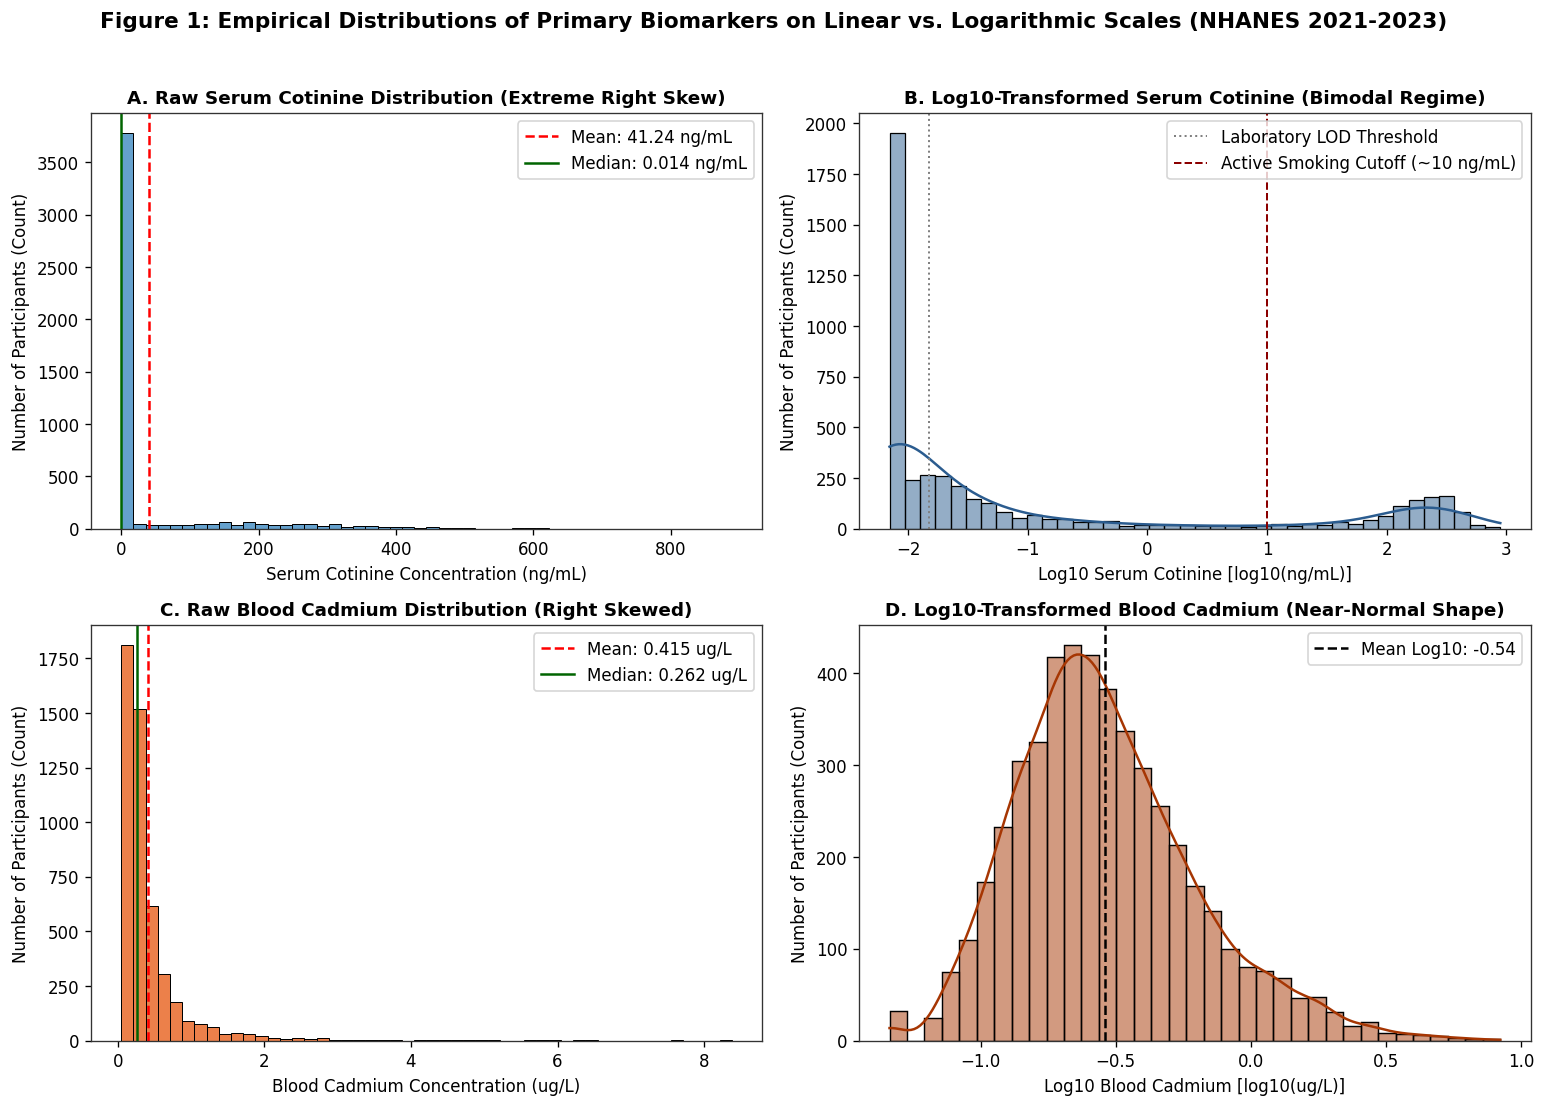

/content/drive/MyDrive/NHANES-Tobacco-Biomarkers/src/descriptive_stats.py:298: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/content/drive/MyDrive/NHANES-Tobacco-Biomarkers/src/descriptive_stats.py:308: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


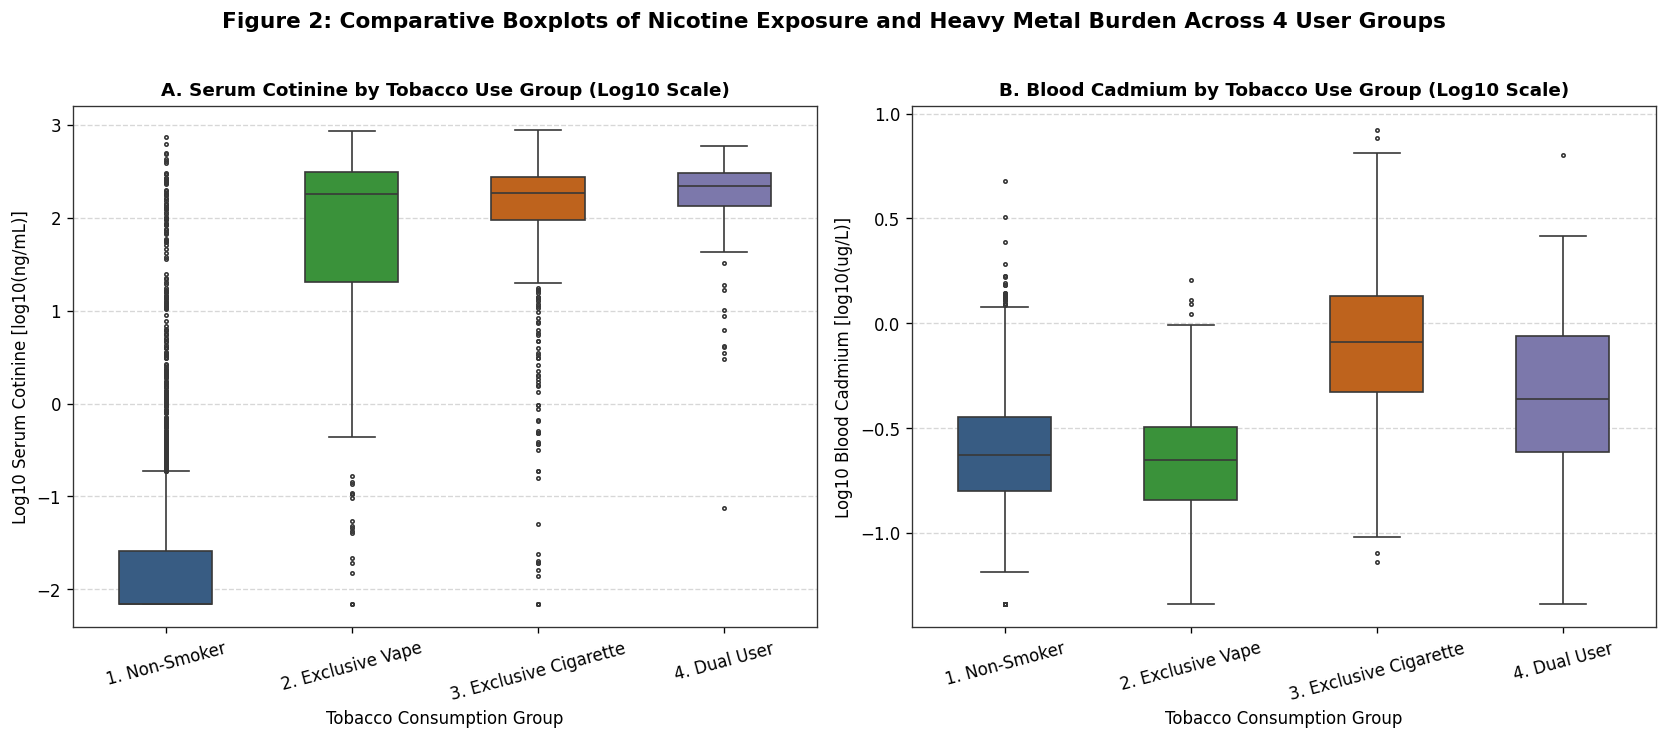

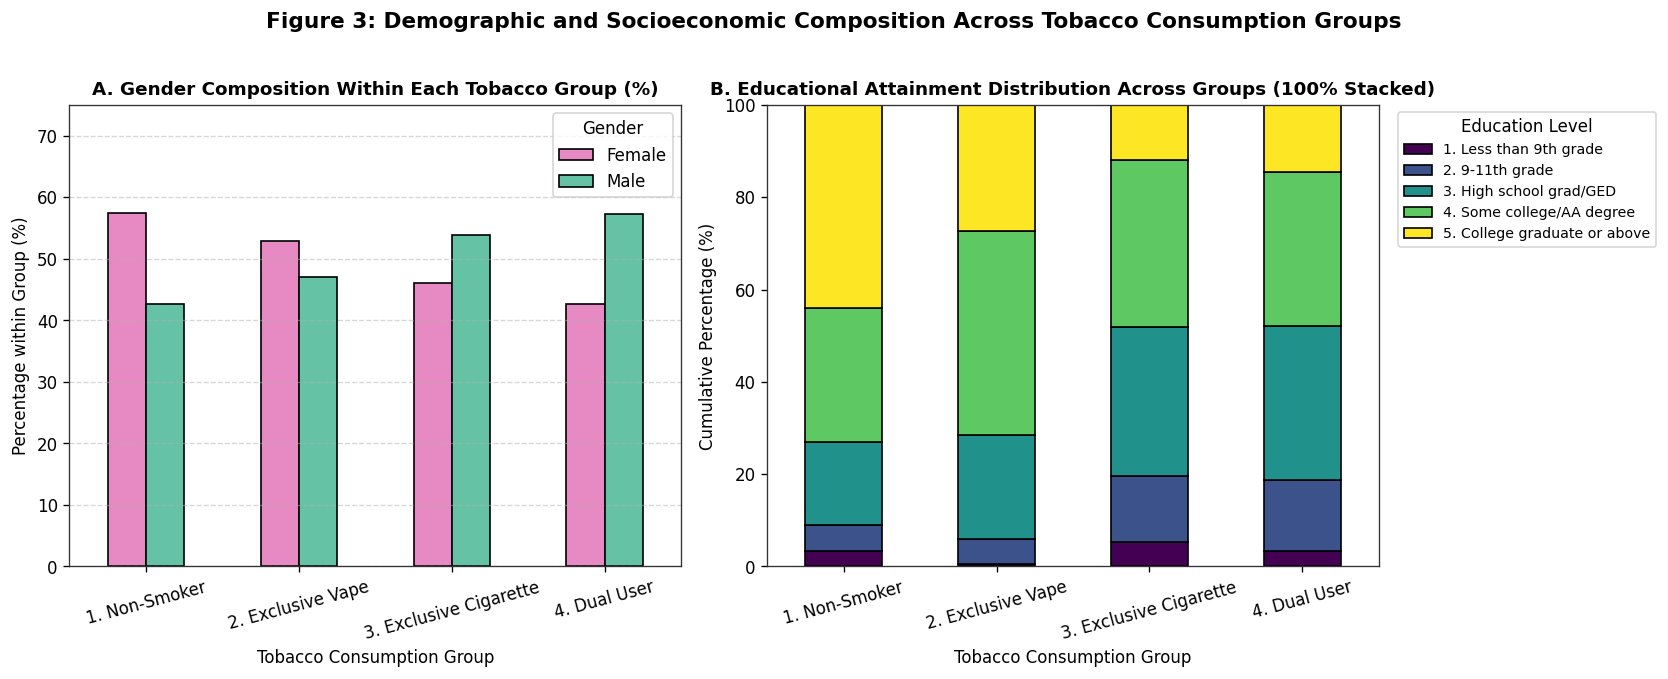

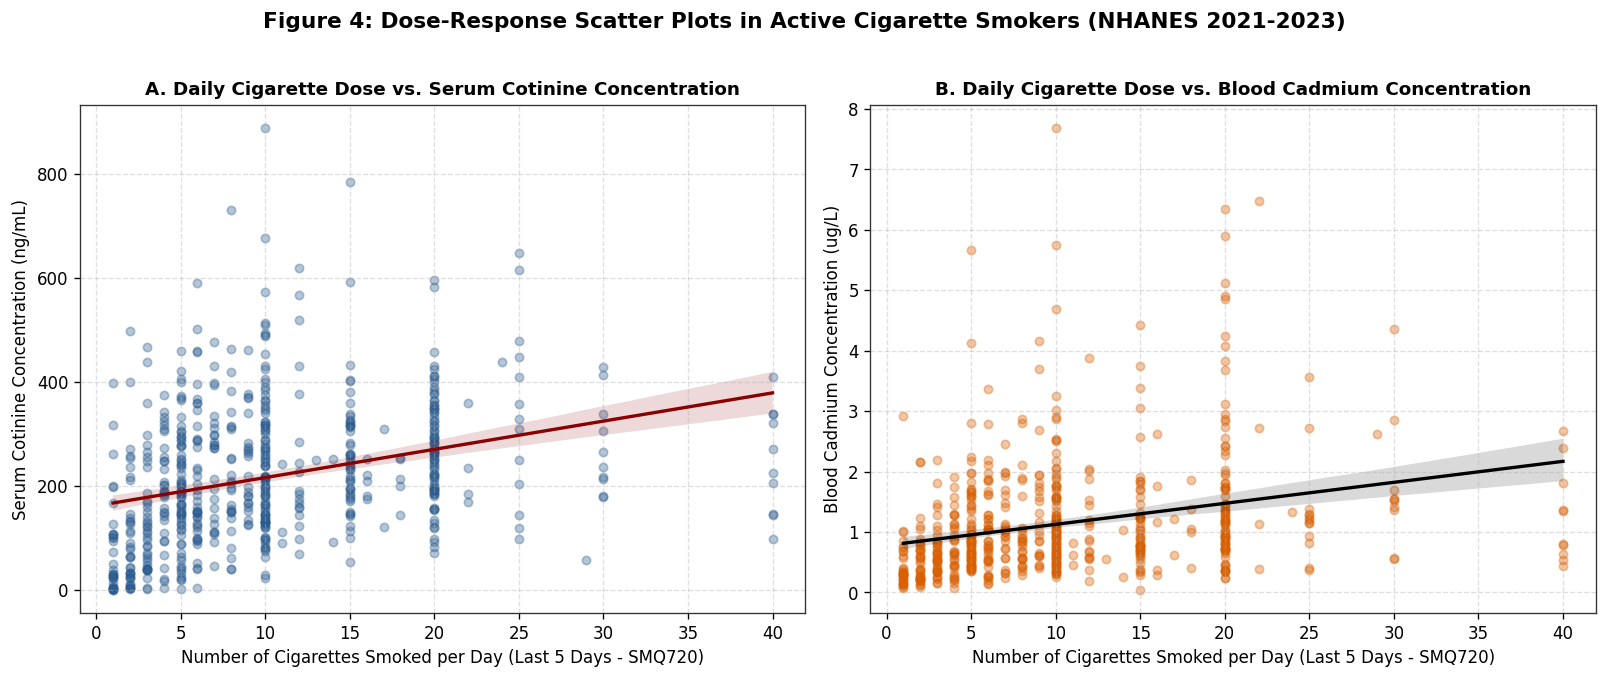


نمودارهای زیر با کیفیت 300 DPI در پوشه figures ذخیره شدند:
 - figures/fig1_biomarker_distributions.png
 - figures/fig2_group_boxplots.png
 - figures/fig3_demographic_bars.png
 - figures/fig4_dose_response_scatter.png


In [20]:
from src.descriptive_stats import create_phase1_visualizations

saved_figs = create_phase1_visualizations(df_adults_labeled, output_dir="figures")
print("\nنمودارهای زیر با کیفیت 300 DPI در پوشه figures ذخیره شدند:")
for path in saved_figs:
    print(" -", path)

In [21]:
from src.descriptive_stats import generate_group_comparison_tables

df_group_long, df_group_pivot = generate_group_comparison_tables(df_adults_labeled)

print("=== جدول ۹-۱: مقایسه توصیفی میانگین، میانه و IQR متغیرهای کمی در ۴ گروه مصرف دخانیات ===")
display(df_group_pivot)

print("\n=== جدول ۹-۲: جزئیات کامل به تفکیک گروه و متغیر ===")
display(df_group_long)

=== جدول ۹-۱: مقایسه توصیفی میانگین، میانه و IQR متغیرهای کمی در ۴ گروه مصرف دخانیات ===


Mean                                           \
Smoking_Group 1. Non-Smoker 2. Exclusive Vape 3. Exclusive Cigarette   
Variable                                                               
INDFMPIR              3.237             2.911                  2.052   
LBXBCD                0.290             0.280                  1.082   
LBXBPB                0.938             0.746                  1.222   
LBXBSE              181.862           181.024                177.445   
LBXCOT                2.972           187.476                195.491   
LBXHCOT               1.525            84.101                 93.781   
LBXHGB               13.826            14.033                 14.291   
LBXWBCSI              6.727             7.169                  7.667   
RIDAGEYR             55.191            38.464                 53.165   

                                  Median                    \
Smoking_Group 4. Dual User 1. Non-Smoker 2. Exclusive Vape   
Variable                                                     
INDFMPIR             2.291         3.350             2.850   
LBXBCD               0.710         0.235             0.222   
LBXBPB               1.132         0.718             0.623   
LBXBSE             180.383       178.100           180.800   
LBXCOT             215.231         0.007           180.500   
LBXHCOT            103.620         0.003            62.300   
LBXHGB              14.420        13.800            14.000   
LBXWBCSI             7.870         6.500             6.800   
RIDAGEYR            40.256        59.000            34.000   

                                                            IQR  \
Smoking_Group 3. Exclusive Cigarette 4. Dual User 1. Non-Smoker   
Variable                                                          
INDFMPIR                       1.680        1.955         3.215   
LBXBCD                         0.819        0.436         0.199   
LBXBPB                         0.991        0.735         0.636   
LBXBSE                       176.400      176.600        29.200   
LBXCOT                       183.000      219.000         0.019   
LBXHCOT                       75.750       75.300         0.008   
LBXHGB                        14.400       14.600         1.800   
LBXWBCSI                       7.500        7.500         2.300   
RIDAGEYR                      56.000       36.000        29.000   

                                                                     
Smoking_Group 2. Exclusive Vape 3. Exclusive Cigarette 4. Dual User  
Variable                                                             
INDFMPIR                  3.035                  2.080        2.375  
LBXBCD                    0.179                  0.880        0.626  
LBXBPB                    0.489                  0.805        0.546  
LBXBSE                   23.775                 29.700       29.150  
LBXCOT                  287.900                182.700      168.500  
LBXHCOT                 126.810                 97.825       94.500  
LBXHGB                    2.100                  2.000        1.500  
LBXWBCSI                  3.000                  2.800        2.800  
RIDAGEYR                 25.250                 22.000       25.000


=== جدول ۹-۲: جزئیات کامل به تفکیک گروه و متغیر ===


,Smoking_Group,Variable,Valid_N,Mean,SD,Median,IQR
0,1. Non-Smoker,LBXCOT,3735,2.972,29.011,0.007,0.019
1,1. Non-Smoker,LBXHCOT,3736,1.525,17.260,0.003,0.008
2,1. Non-Smoker,LBXBCD,3877,0.290,0.215,0.235,0.199
3,1. Non-Smoker,LBXBPB,3877,0.938,1.209,0.718,0.636
4,1. Non-Smoker,LBXBSE,3877,181.862,30.266,178.100,29.200
5,1. Non-Smoker,LBXHGB,3878,13.826,1.403,13.800,1.800
6,1. Non-Smoker,LBXWBCSI,3878,6.727,1.929,6.500,2.300
7,1. Non-Smoker,RIDAGEYR,4031,55.191,17.173,59.000,29.000
8,1. Non-Smoker,INDFMPIR,3526,3.237,1.616,3.350,3.215
9,2. Exclusive Vape,LBXCOT,146,187.476,169.572,180.500,287.900


In [22]:
import sys
if 'src.survey_design' in sys.modules:
    del sys.modules['src.survey_design']

from src.survey_design import (
    summarize_sampling_weights,
    define_analytic_population,
    compare_unweighted_vs_weighted
)

# ۱. خلاصه توزیع وزن‌های نمونه‌گیری در بزرگسالان (مکمل تسک الف-۲)
df_weights_info = summarize_sampling_weights(df_cleaned)
print("=== جدول الف-۲: خلاصه توزیع وزن‌های نمونه‌گیری و جمعیت برآوردشده آمریکا ===")
display(df_weights_info)

# ۲. تعریف جمعیت تحلیلی نهایی و گزارش افراد حذف‌شده در هر گام (تسک الف-۴)
df_analytic, df_flow_report = define_analytic_population(df_cleaned)
print("\n=== جدول الف-۴: فلوچارت معیارهای ورود و خروج و تعداد افراد حذف‌شده در هر مرحله ===")
display(df_flow_report)

print("\nتوزیع نهایی ۴ گروه مصرف دخانیات در جمعیت تحلیلی نهایی (df_analytic):")
print(df_analytic["Smoking_Group"].value_counts().sort_index())

=== جدول الف-۲: خلاصه توزیع وزن‌های نمونه‌گیری و جمعیت برآوردشده آمریکا ===


,Weight_Variable,Description,Positive_Weights_N,Sum_of_Weights (Estimated US Adult Pop),Min_Weight (Min Persons Represented),Median_Weight,Mean_Weight,Max_Weight (Max Persons Represented),Max_to_Min_Ratio
0,WTINT2YR,Interview 2-Year Weight (All Interviewed Adults),7809,245061169,4584.5,25135.1,31381.9,170968.3,37.3
1,WTMEC2YR,MEC Exam 2-Year Weight (Examined Adults),6064,245061169,4581.6,31816.9,40412.5,227108.3,49.6
2,WTPH2YR,Phlebotomy 2-Year Weight (Blood Draw Subsample),5792,245061169,4391.8,33332.9,42310.3,241728.9,55.0



=== جدول الف-۴: فلوچارت معیارهای ورود و خروج و تعداد افراد حذف‌شده در هر مرحله ===


,Step_Number,Criterion_Description,Remaining_N,Excluded_in_Step,Cumulative_Excluded,Retention_Rate (%)
0,0,Total participants in merged NHANES 2021-2023 ...,11933,0,0,100.00
1,1,Target age restriction: Adults aged >= 20 year...,7809,4124,4124,65.44
2,2,Valid Phlebotomy sampling weight (WTPH2YR > 0;...,5792,2017,6141,48.54
3,3,Non-missing primary outcomes: Serum Cotinine (...,5520,272,6413,46.26
4,4,"Exclude recent NRT (SMQ863=1), Hookah (SMQ845=...",5368,152,6565,44.98
5,5,Complete smoking/vaping questionnaire data to ...,4655,713,7278,39.01



توزیع نهایی ۴ گروه مصرف دخانیات در جمعیت تحلیلی نهایی (df_analytic):
Smoking_Group
1. Non-Smoker             3734
2. Exclusive Vape          146
3. Exclusive Cigarette     672
4. Dual User               103
Name: count, dtype: int64


In [23]:
df_w_quant, df_w_cat = compare_unweighted_vs_weighted(df_analytic)

print("=== جدول الف-۳ (بخش اول): مقایسه میانگین و میانه خام و وزن‌دار (WTPH2YR) ===")
display(df_w_quant)

print("\n=== جدول الف-۳ (بخش دوم): مقایسه نسبت‌ها (درصدها) در حالت خام و وزن‌دار ===")
display(df_w_cat)

=== جدول الف-۳ (بخش اول): مقایسه میانگین و میانه خام و وزن‌دار (WTPH2YR) ===


,Variable,Description,Valid_N,Unweighted_Mean,Weighted_Mean,Mean_Diff (W - Unw),Relative_Change (%),Unweighted_Median,Weighted_Median
0,RIDAGEYR,Age (Years),4655,54.133,48.997,-5.136,-9.49,58.000,49.000
1,INDFMPIR,Income-to-Poverty Ratio,4103,3.071,3.139,0.067,2.20,3.080,3.220
2,LBXCOT,Serum Cotinine (ng/mL) - All,4655,41.248,41.714,0.465,1.13,0.014,0.016
3,LBXBCD,Blood Cadmium (ug/L) - All,4655,0.408,0.378,-0.030,-7.24,0.262,0.238
4,LBXBPB,Blood Lead (ug/dL) - All,4655,0.973,0.891,-0.082,-8.41,0.742,0.672
5,LBXHGB,Hemoglobin (g/dL),4638,13.909,14.000,0.091,0.65,13.900,14.100
6,LBXWBCSI,White Blood Cell Count (1000/uL),4638,6.890,6.899,0.009,0.13,6.600,6.600
7,LBXCOT (2. Exclusive Vape),Cotinine in 2. Exclusive Vape,146,187.476,201.020,13.544,7.22,180.500,191.000
8,LBXBCD (2. Exclusive Vape),Cadmium in 2. Exclusive Vape,146,0.274,0.236,-0.038,-13.76,0.218,0.183
9,LBXCOT (3. Exclusive Cigarette),Cotinine in 3. Exclusive Cigarette,672,195.491,182.137,-13.354,-6.83,183.000,175.000



=== جدول الف-۳ (بخش دوم): مقایسه نسبت‌ها (درصدها) در حالت خام و وزن‌دار ===


,Category_Group,Category_Level,Sample_Count (n),Unweighted_Percent (%),Weighted_Percent (%),Difference (W - Unw %)
0,Tobacco Use Group,1. Non-Smoker,3734,80.21,79.42,-0.80
1,Tobacco Use Group,2. Exclusive Vape,146,3.14,3.86,0.73
2,Tobacco Use Group,3. Exclusive Cigarette,672,14.44,13.99,-0.44
3,Tobacco Use Group,4. Dual User,103,2.21,2.73,0.52
4,Age Bracket,Older Adults (Aged >= 60 Years),2178,46.79,31.82,-14.97
5,Race / Ethnicity,Non-Hispanic White,2896,62.21,62.62,0.40
6,Race / Ethnicity,Non-Hispanic Black,499,10.72,10.49,-0.23
